The Qiskit SDK includes a library of popular circuits to use as building blocks in your own programs. Using pre-defined circuits saves time researching, writing code, and debugging. The library includes popular circuits in quantum computing, circuits that are difficult to simulate classically, and circuits useful for quantum hardware benchmarking.

This page lists the different circuit categories the library provides. For a full list of circuits, see the

Standard gates
The circuit library also includes standard quantum gates. Some are more fundamental gates (such as the UGate), and others are multi-qubit gates that usually need building from single- and two-qubit gates. To add imported gates to your circuit, use the append method; the first argument is the gate, and the next argument is a list of qubits to apply the gate to.

For example, the following code cell creates a circuit with a Hadamard gate and a multi-controlled-X gate.

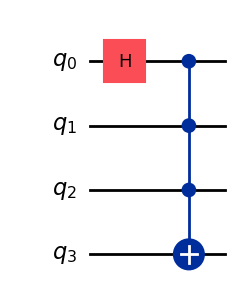

In [1]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import HGate, MCXGate

mcx_gate = MCXGate(3)
hadamard_gate = HGate()
qc = QuantumCircuit(4)
qc.append(hadamard_gate, [0])
qc.append(mcx_gate, [0, 1, 2, 3])
qc.draw("mpl")

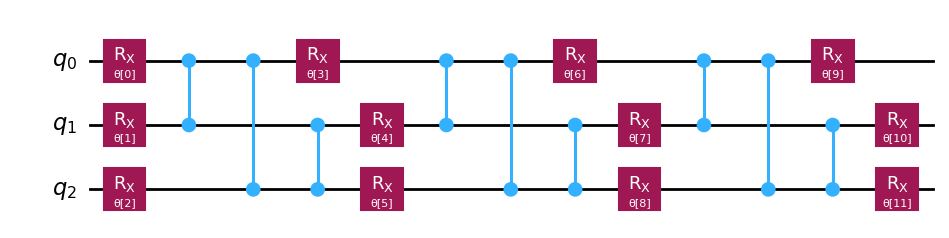

In [2]:
from qiskit.circuit.library import n_local

two_local = n_local(3, "rx", "cz")
two_local.draw("mpl")

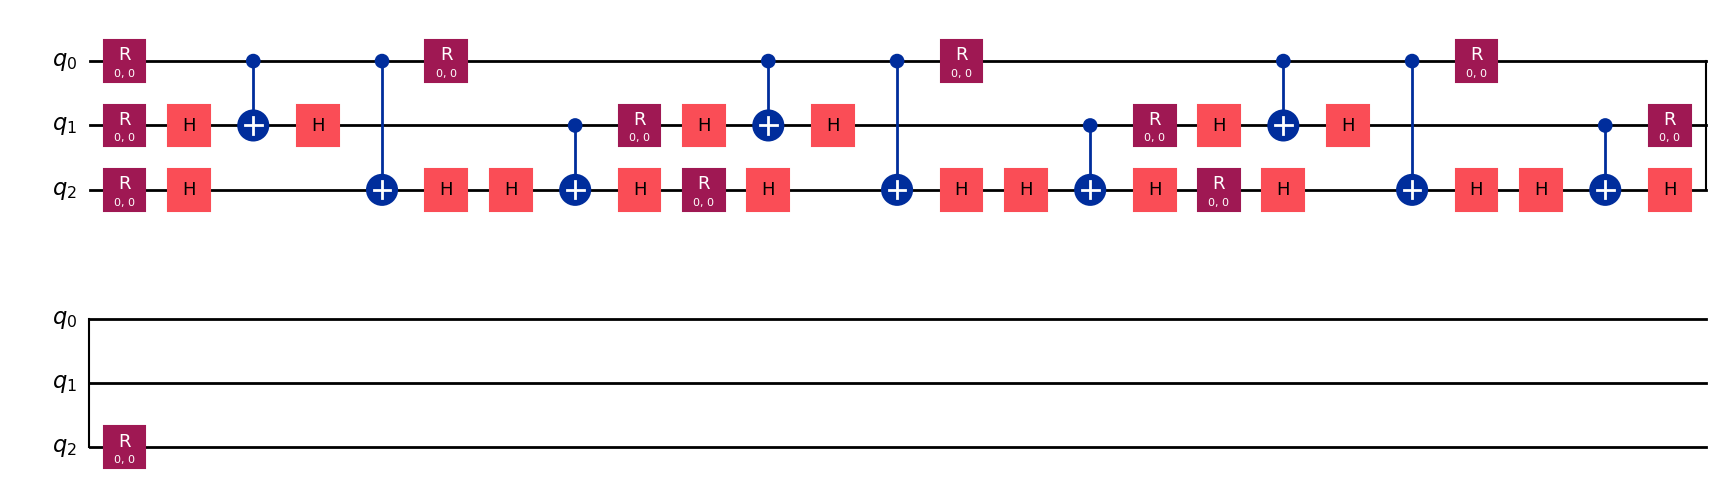

In [3]:
bound_circuit = two_local.assign_parameters(
    {p: 0 for p in two_local.parameters}
)
bound_circuit.decompose().draw("mpl")

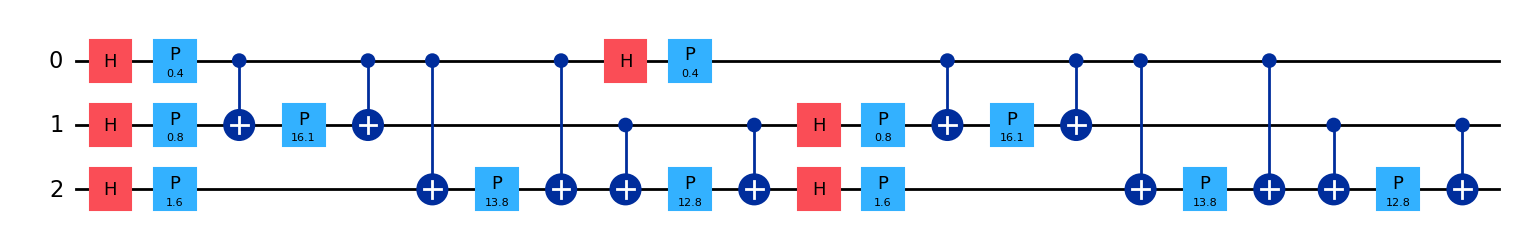

In [4]:
from qiskit.circuit.library import zz_feature_map

features = [0.2, 0.4, 0.8]
feature_map = zz_feature_map(feature_dimension=len(features))

encoded = feature_map.assign_parameters(features)
encoded.draw("mpl")

Deferred timing resolution using stretch
The OpenQASM 3 language specification contains a stretch type with which you can specify relative timing of operations instead of absolute timing. Support for stretch as durations for Delay instructions was added in Qiskit v2.0.0. The concrete value of a stretch duration is resolved at compile time, after the exact duration of calibrated gates are known. The compiler tries to minimize the stretch duration, subject to timing constraints on one or more qubits. You can then express gate designs such as evenly spacing gates (for example, to implement a higher-order echo decoupling sequence), left-aligning a sequence of gates, or applying a gate for the duration of some sub-circuit, without knowing the exact timing.

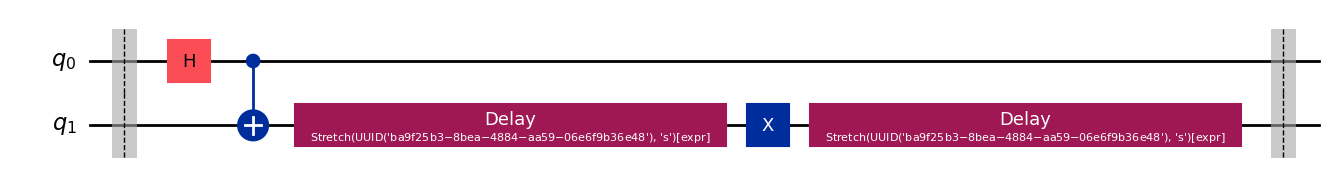

In [6]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(2)

# Synchronization boundary
qc.barrier()

# Operations on qubit 0
qc.h(0)
qc.cx(0, 1)

# Symbolic delay on qubit 1
s = qc.add_stretch("s")

qc.delay(s, 1)
qc.x(1)
qc.delay(s, 1)

# End synchronization boundary
qc.barrier()

qc.draw("mpl")